In [2]:
!pip install -q hdbscan

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [4]:
from google.colab import files
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset berhasil dibaca!")
display(df.head())

print("Ukuran dataset:", df.shape)

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset berhasil dibaca!


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Ukuran dataset: (200, 5)


In [5]:
# Mengambil kolom numerik
X = df.select_dtypes(include=np.number).copy()

# Menghapus kolom yang seluruh nilainya kosong
X = X.dropna(axis=1, how='all')

# Mengatasi missing values
X = X.fillna(X.median())

# Menghapus kolom konstan
X = X.loc[:, X.nunique() > 1]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)

print("Dimensi data:", X.shape)
print("Persiapan dataset selesai!")

Dimensi data: (200, 4)
Persiapan dataset selesai!


In [6]:
def plot(X, labels, probabilities, param, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    X_plot = np.asarray(X)

    # Mengubah data menjadi 2 dimensi jika diperlukan
    if X_plot.shape[1] > 2:
        X_plot = PCA(n_components=2).fit_transform(X_plot)

    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)

    scatter = ax.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=labels,
        cmap='viridis',
        s=30,
        alpha=0.7
    )

    ax.set_title(f"HDBSCAN Clustering: {param}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

    return scatter

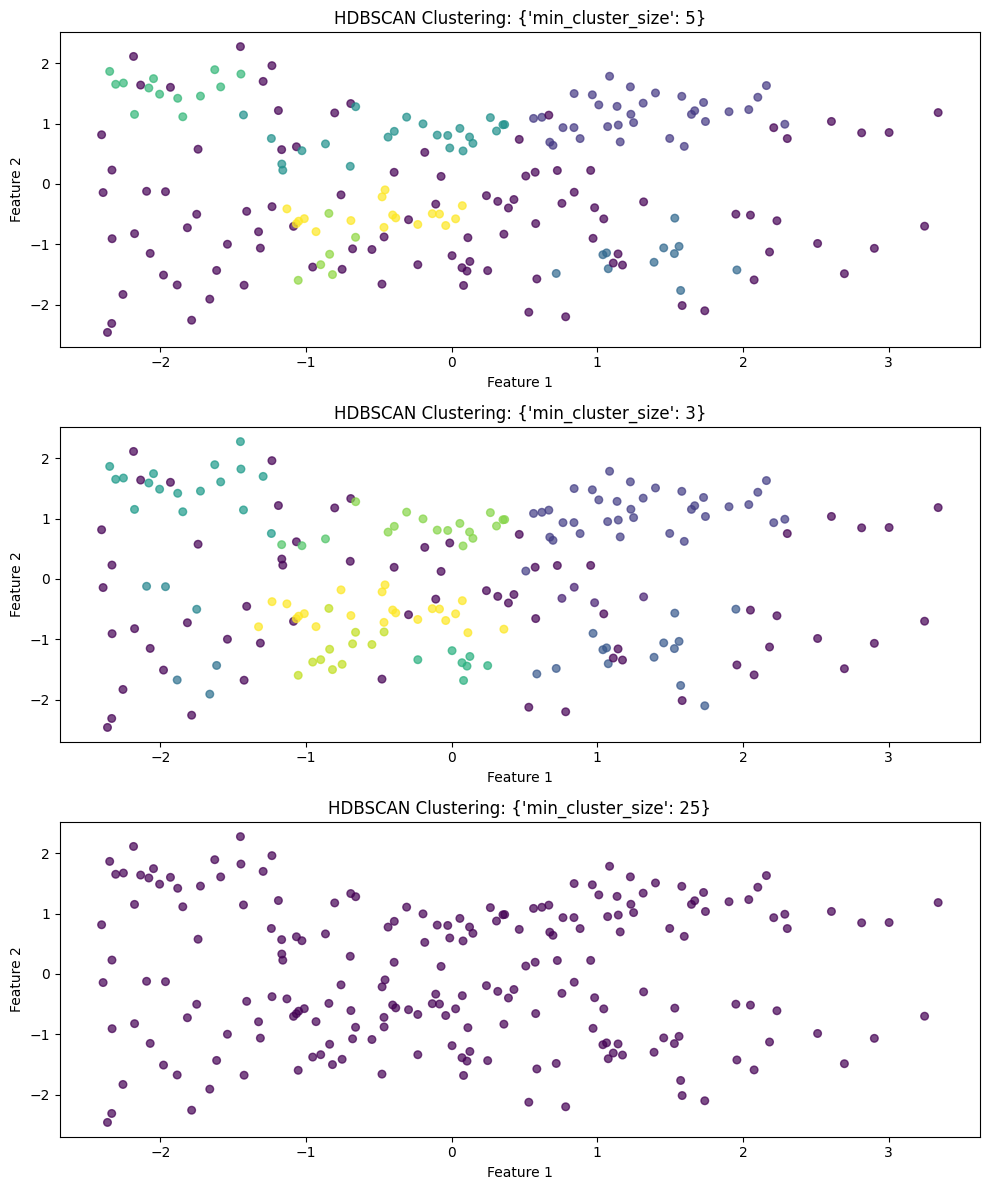

In [7]:
PARAM = (
    {"min_cluster_size": 5},
    {"min_cluster_size": 3},
    {"min_cluster_size": 25}
)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.tight_layout()
plt.show()

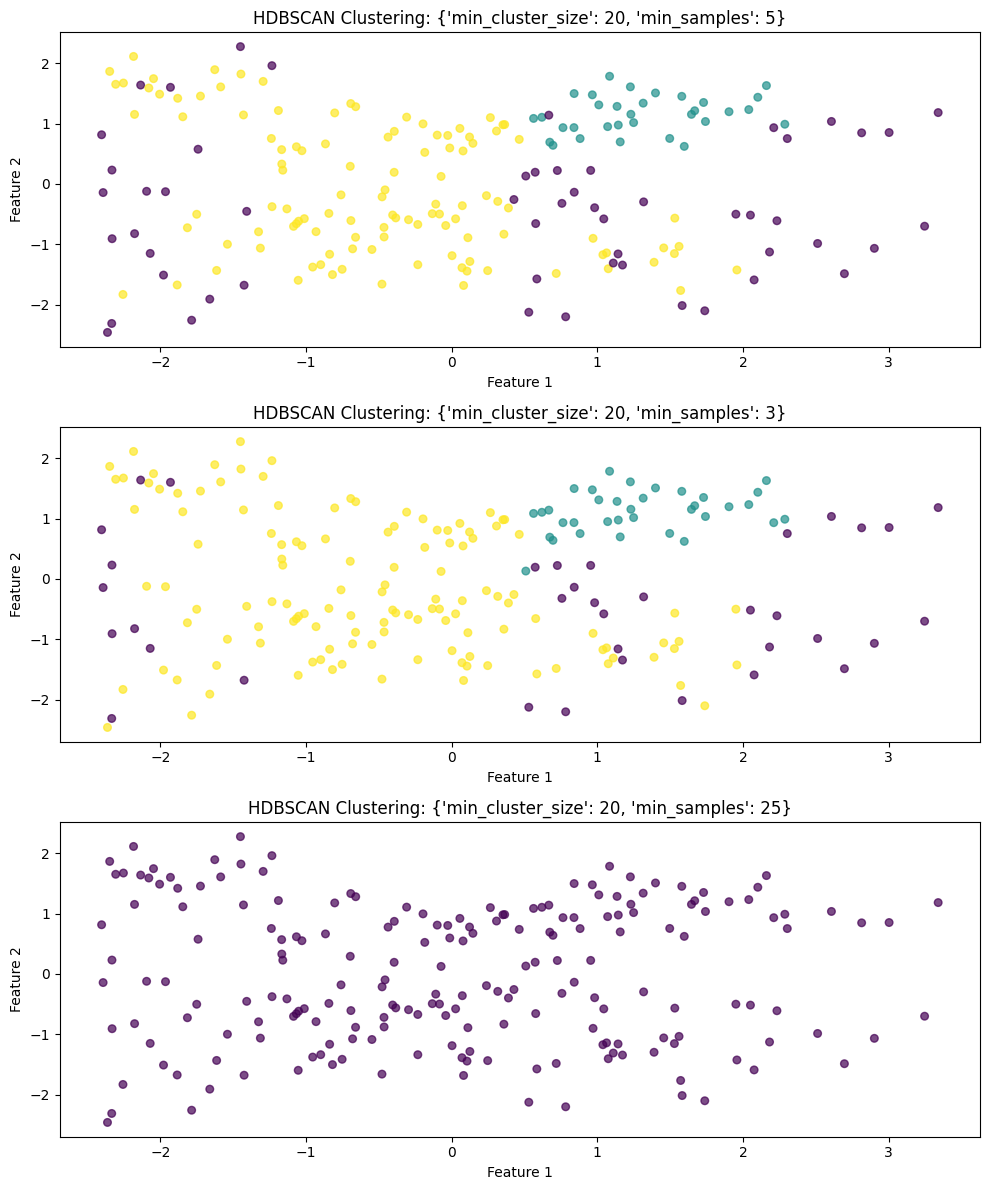

In [8]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.tight_layout()
plt.show()

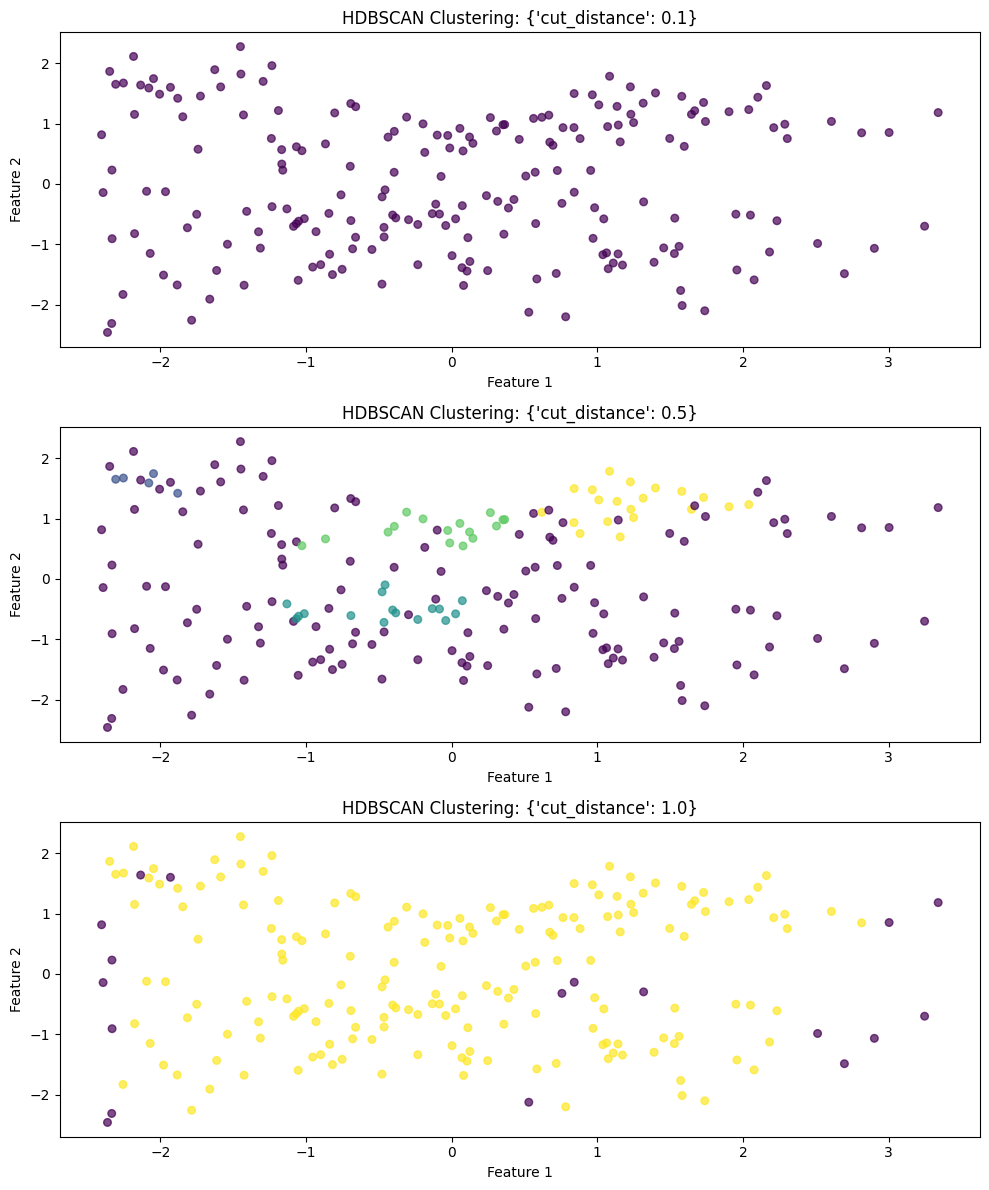

In [9]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)

hdb = hdbscan.HDBSCAN().fit(X)

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)

    plot(
        X,
        labels,
        hdb.probabilities_,
        param,
        ax=axes[i]
    )

plt.tight_layout()
plt.show()

In [10]:
# Membuat model HDBSCAN
hdb_eval = hdbscan.HDBSCAN(
    min_cluster_size=20,
    min_samples=5
).fit(X)

labels = hdb_eval.labels_

# Mengabaikan noise (-1)
mask = labels != -1

X_valid = X[mask]
labels_valid = labels[mask]

n_clusters = len(np.unique(labels_valid))

if 2 <= n_clusters < len(X_valid):
    sil_score = silhouette_score(X_valid, labels_valid)
    print(f"Silhouette Score: {sil_score:.4f}")
else:
    sil_score = None
    print("Silhouette Score tidak dapat dihitung.")
    print("Jumlah cluster valid harus minimal 2.")

Silhouette Score: 0.3251


In [11]:
if 2 <= n_clusters < len(X_valid):
    dbi_score = davies_bouldin_score(X_valid, labels_valid)
    print(f"Davies-Bouldin Index: {dbi_score:.4f}")
else:
    dbi_score = None
    print("Davies-Bouldin Index tidak dapat dihitung.")

Davies-Bouldin Index: 0.9316


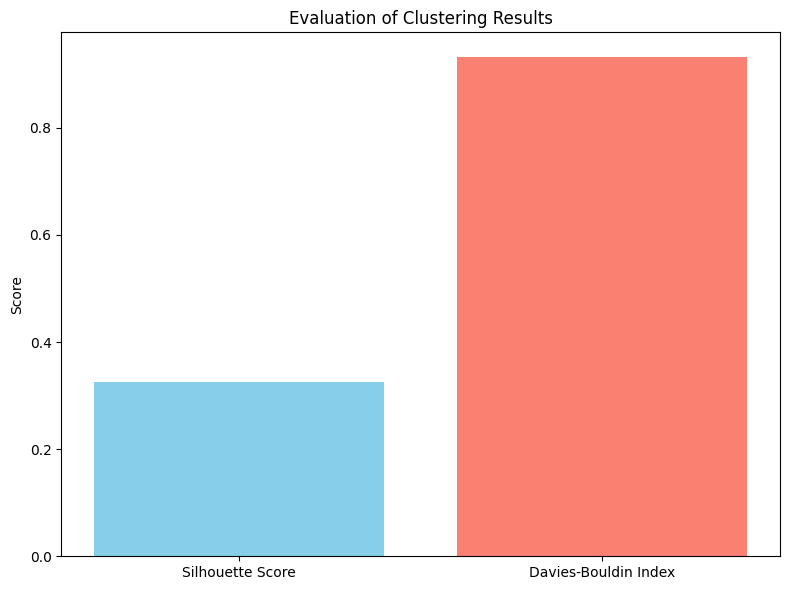

In [12]:
scores = {}

if sil_score is not None:
    scores["Silhouette Score"] = sil_score

if dbi_score is not None:
    scores["Davies-Bouldin Index"] = dbi_score

if scores:
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.bar(
        scores.keys(),
        scores.values(),
        color=['skyblue', 'salmon'][:len(scores)]
    )

    ax.set_title("Evaluation of Clustering Results")
    ax.set_ylabel("Score")

    plt.tight_layout()
    plt.show()
else:
    print("Belum ada hasil evaluasi yang dapat ditampilkan.")

In [13]:
unique_labels = np.unique(labels)

n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah data noise:", n_noise)
print("Total data:", len(labels))

print("\nDistribusi anggota cluster:")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster: 2
Jumlah data noise: 55
Total data: 200

Distribusi anggota cluster:
-1     55
 0     32
 1    113
Name: count, dtype: int64
